# PharmaFlow by WaadAlwagdani
## Delivery performance and cost in global HIV & malaria medicine supply chains

**Author:** Waad Alwagdani, PharmD (وعد الوقداني) · © 2026 All rights reserved.

**Data:** USAID Supply Chain Management System (SCMS) delivery history, 10,324 shipment lines of ARVs and HIV/malaria test kits to 43 countries, 2006–2015. Public US government data.

**Questions a supply chain pharmacist would ask**
1. How reliably did medicines arrive on time, and did it change over the years?
2. When shipments were late, how late?
3. Which channel performs better: shipping directly from the manufacturer, or through regional distribution centres (RDCs)?
4. What does each shipment mode cost per kilogram, and is faster freight actually more punctual?
5. Which countries and vendors drive the delays?
6. How did the price of the first-line ARV regimen change?

In [1]:
import sys; sys.path.insert(0, "..")
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import pharmaflow as pf
from pharmaflow import cleaning, metrics, viz

viz.set_theme()
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 40)

## 1. Load the raw data
The export is Latin-1 encoded (country names like *Côte d'Ivoire*), with 33 columns and long, inconsistent names.

In [2]:
raw = pf.load_raw()
print(raw.shape)
raw.head(3).T

(10324, 33)


,0,1,2
ID,1,3,4
Project Code,100-CI-T01,108-VN-T01,100-CI-T01
PQ #,Pre-PQ Process,Pre-PQ Process,Pre-PQ Process
PO / SO #,SCMS-4,SCMS-13,SCMS-20
ASN/DN #,ASN-8,ASN-85,ASN-14
Country,Côte d'Ivoire,Vietnam,Côte d'Ivoire
Managed By,PMO - US,PMO - US,PMO - US
Fulfill Via,Direct Drop,Direct Drop,Direct Drop
Vendor INCO Term,EXW,EXW,FCA
Shipment Mode,Air,Air,Air


## 2. Data quality audit
Before cleaning, find where the data is not what its column name promises.

In [3]:
for col in ["Weight (Kilograms)", "Freight Cost (USD)"]:
    text = raw[col][pd.to_numeric(raw[col], errors="coerce").isna()]
    print(f"\n{col}: {len(text):,} non-numeric values")
    print(text.str.replace(r"\d+", "#", regex=True).value_counts().to_string())


Weight (Kilograms): 3,952 non-numeric values
Weight (Kilograms)
See DN-# (ID#:#)              1937
Weight Captured Separately    1507
See ASN-# (ID#:#)              508

Freight Cost (USD): 4,126 non-numeric values
Freight Cost (USD)
See DN-# (ID#:#)                      1937
Freight Included in Commodity Cost    1442
See ASN-# (ID#:#)                      508
Invoiced Separately                    239


In [4]:
for col in ["PQ First Sent to Client Date", "PO Sent to Vendor Date"]:
    print(f"\n{col}")
    print(raw[col].str.replace(r"\d", "9", regex=True).value_counts().head(5).to_string())


PQ First Sent to Client Date
PQ First Sent to Client Date
9/99/9999         4157
Pre-PQ Process    2476
9/9/9999          1450
99/99/9999        1425
99/9/9999          611

PO Sent to Vendor Date
PO Sent to Vendor Date
N/A - From RDC    5404
9/99/9999         2707
9/9/9999           852
99/99/9999         631
99/9/9999          402


**Findings**
* Weight and freight are stored as text. About 40% of rows hold notes instead of numbers.
* "See DN-304 (ID#:10589)" means the line shares a shipment with line 10589, so its weight and freight are recorded there.
* "Freight Included in Commodity Cost" means a freight cost of **0** on this line, not missing data.
* Dates come in two formats (`2-Jun-06` and `9/11/2014`), mixed with notes such as *Pre-PQ Process* and *N/A - From RDC*.

## 3. Cleaning pipeline
Each step is a function in `pharmaflow/cleaning.py`, chained with `DataFrame.pipe`:

```python
raw.pipe(rename_columns).pipe(parse_dates).pipe(parse_weight_and_freight).pipe(fill_categories).pipe(add_features)
```

Key decisions:
* **References are followed** for weight, so a line pointing to another line gets that line's weight.
* **Shared freight is counted once**: referencing lines get no freight of their own, so totals are not inflated.
* **Derived features**: delay (delivered − scheduled), on-time flag, lead time (PO → delivery), freight as % of commodity value, and freight per kg.

In [5]:
df = cleaning.clean(raw)
cleaning.quality_report(raw, df)

,check,raw,clean
0,Rows,"10,324.00",10324
1,Duplicate IDs,0.00,0
2,Missing shipment mode,360.00,360
3,Weight not numeric,"3,952.00",1633
4,Freight not numeric,"4,126.00",2684
5,PO date missing,NaN,5732


In [6]:
pd.concat({"weight": df["weight_status"].value_counts(), "freight": df["freight_status"].value_counts()}, axis=1).fillna(0).astype(int)

,weight,freight
recorded,6372,6198
reference,2445,2445
Weight Captured Separately,1507,0
Freight Included in Commodity Cost,0,1442
Invoiced Separately,0,239


In [7]:
df.to_csv("../data/processed/shipments_clean.csv", index=False)
df[["id", "country", "shipment_mode", "scheduled_date", "delivered_date", "delay_days", "on_time",
    "value_usd", "freight_usd", "weight_kg", "freight_pct_of_value", "freight_per_kg"]].head()

,id,country,shipment_mode,scheduled_date,delivered_date,delay_days,on_time,value_usd,freight_usd,weight_kg,freight_pct_of_value,freight_per_kg
0,1,Côte d'Ivoire,Air,2006-06-02,2006-06-02,0,True,551.00,780.34,13.00,141.62,60.03
1,3,Vietnam,Air,2006-11-14,2006-11-14,0,True,"6,200.00","4,521.50",358.00,72.93,12.63
2,4,Côte d'Ivoire,Air,2006-08-27,2006-08-27,0,True,"40,000.00","1,653.78",171.00,4.13,9.67
3,15,Vietnam,Air,2006-09-01,2006-09-01,0,True,"127,360.80","16,007.06","1,855.00",12.57,8.63
4,16,Vietnam,Air,2006-08-11,2006-08-11,0,True,"121,600.00","45,450.08","7,590.00",37.38,5.99


## 4. Headline KPIs

In [8]:
k = metrics.kpis(df)
pd.Series({
    "Shipment lines": f"{k['shipments']:,}",
    "Countries / vendors": f"{k['countries']} / {k['vendors']}",
    "Commodity value": f"${k['value_usd']/1e9:,.2f} B",
    "Recorded freight": f"${k['freight_usd']/1e6:,.1f} M",
    "On-time rate": f"{k['on_time_rate']:.1f}%",
    "Median delay when late": f"{k['median_delay_when_late']:.0f} days",
    "Median PO-to-delivery lead time": f"{k['median_lead_time']:.0f} days",
    "Median freight as % of value": f"{k['freight_pct_median']:.1f}%",
}).to_frame("value")

,value
Shipment lines,"10,324"
Countries / vendors,43 / 73
Commodity value,$1.63 B
Recorded freight,$68.8 M
On-time rate,88.5%
Median delay when late,12 days
Median PO-to-delivery lead time,92 days
Median freight as % of value,7.3%


## 5. Reliability over time

findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


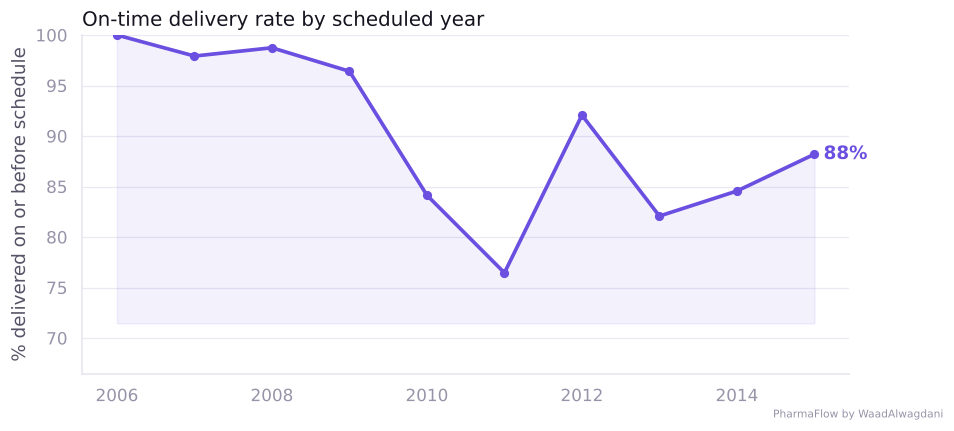

,shipments,on_time_rate,mean_delay_days,median_lead_time
year,,,,
2006,65,100.00,-1.06,41.50
2007,672,97.92,0.31,68.00
2008,1029,98.74,-4.21,69.00
2009,1253,96.41,-15.37,56.00
2010,1204,84.14,-5.55,98.00
2011,1011,76.46,-0.20,129.00
2012,1273,92.07,-13.89,97.00
2013,1272,82.08,-2.83,110.00
2014,1528,84.55,-3.20,69.00


In [9]:
fig = viz.on_time_by_year(df); fig.savefig("../reports/figures/on_time_by_year.png"); plt.show()
metrics.yearly(df)[["shipments", "on_time_rate", "mean_delay_days", "median_lead_time"]]

Performance was near-perfect while volumes were small (2006–2009), then dropped to **76.5% in 2011** as volumes and the RDC model scaled up. It recovered in 2012, but never returned to the early levels.

## 6. How late is late?

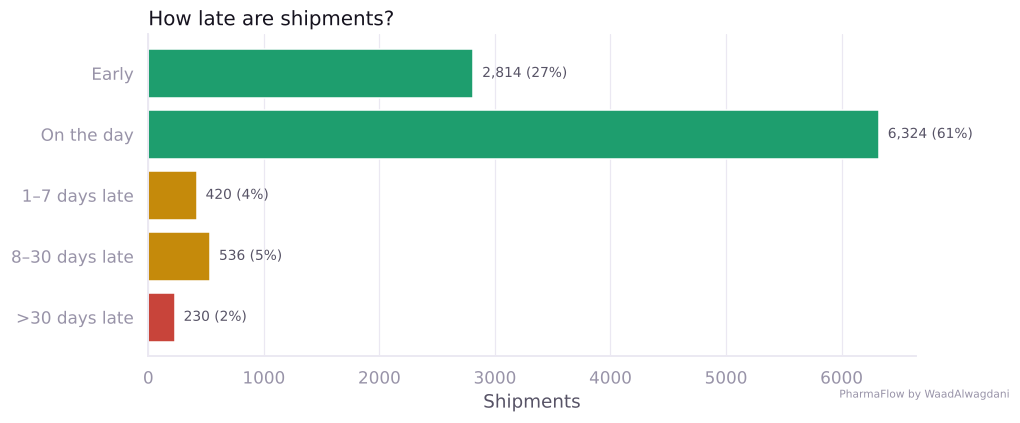

In [10]:
fig = viz.delay_distribution(df); fig.savefig("../reports/figures/delay_distribution.png"); plt.show()

Most late shipments are a week or more behind schedule, not a day or two. For a medicine like an ARV, where treatment must not be interrupted, this is the risk the safety stock has to cover.

## 7. Direct drop vs regional distribution centre

In [11]:
metrics.by(df, "fulfill_via")[["shipments", "value_usd", "on_time_rate", "mean_delay_days", "median_freight_pct"]]

,shipments,value_usd,on_time_rate,mean_delay_days,median_freight_pct
fulfill_via,,,,,
From RDC,5404,"1,085,372,434.95",82.85,-8.28,9.15
Direct Drop,4920,"542,212,022.34",94.74,-3.54,5.94


Shipments **from RDCs were on time 82.8% of the time, against 94.7% for direct drop** from manufacturers. RDC freight is also higher as a share of value (9.1% vs 5.9%). The RDC model brings stock closer to countries, but in this data it did not make delivery more punctual.

## 8. Shipment mode: cost vs punctuality

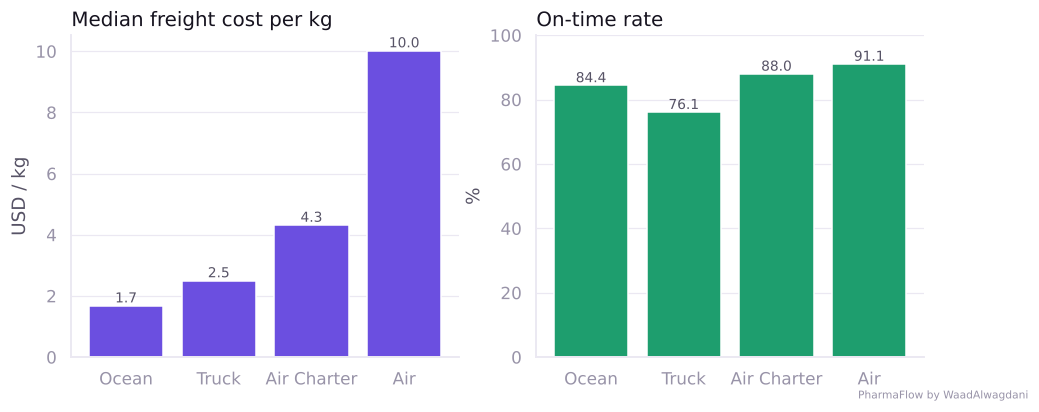

,shipments,median_freight_per_kg,median_freight_pct,on_time_rate,mean_delay_days
shipment_mode,,,,,
Air,4115,10.02,12.61,91.06,-1.51
Truck,1166,2.50,5.89,76.07,-10.14
Air Charter,424,4.32,8.73,87.97,-19.12
Ocean,282,1.68,3.48,84.40,3.88


In [12]:
fig = viz.mode_cost(df); fig.savefig("../reports/figures/mode_cost.png"); plt.show()
metrics.mode_cost_comparison(df)

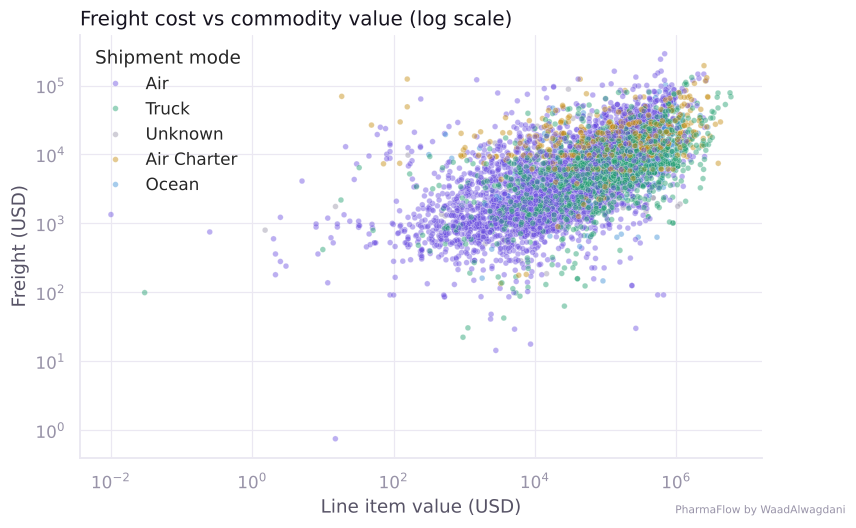

In [13]:
fig = viz.freight_vs_value(df); fig.savefig("../reports/figures/freight_vs_value.png"); plt.show()

Air freight costs about **6× more per kg than ocean** ($10.0 vs $1.7) and is the most punctual mode (91%). Trucks are cheap but have the worst on-time rate (76%). Ocean is cheapest, but averages several days late. Air charter sits between: often early, at less than half the per-kg cost of regular air.

## 9. Countries

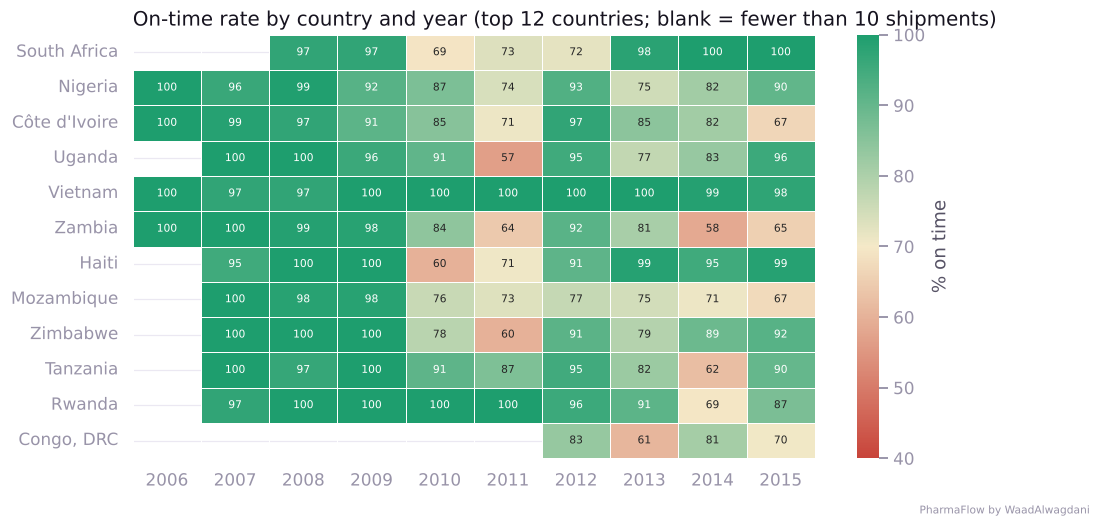

,shipments,value_usd,on_time_rate,mean_delay_days
country,,,,
South Africa,1406,"108,670,145.47",91.82,-12.22
Nigeria,1194,"350,272,104.87",88.11,-11.22
Côte d'Ivoire,1083,"120,884,500.89",87.63,-5.38
Uganda,779,"96,197,336.16",87.42,-7.58
Vietnam,688,"56,974,405.86",99.13,-0.35
Zambia,683,"246,988,840.41",84.19,-5.23
Haiti,655,"43,502,785.90",90.53,-2.43
Mozambique,631,"182,024,690.72",81.62,-1.21
Zimbabwe,538,"104,439,960.51",85.69,-11.01


In [14]:
fig = viz.country_heat(df); fig.savefig("../reports/figures/country_heat.png"); plt.show()
metrics.by(df, "country", 300)[["shipments", "value_usd", "on_time_rate", "mean_delay_days"]]

Nigeria holds the largest commodity value ($350 M). Vietnam was almost always on time (99%), while DR Congo (75%) and Mozambique (82%) were the least reliable among high-volume countries. Zambia and Côte d'Ivoire slipped below 70% in 2014–2015.

## 10. Vendor scorecard

In [15]:
sc = metrics.vendor_scorecard(df, 100)
sc[["shipments", "value_share_pct", "on_time_rate", "mean_delay_days", "late_p90_days"]]

,shipments,value_share_pct,on_time_rate,mean_delay_days,late_p90_days
vendor,,,,,
SCMS from RDC,5404,66.69,82.85,-8.28,9.00
Aurobindo Pharma Limited,668,5.61,85.93,4.41,8.00
CIPLA LIMITED,175,2.44,86.86,4.78,14.00
"Orgenics, Ltd",754,9.08,87.00,0.84,3.00
S. BUYS WHOLESALER,715,0.61,98.46,-28.68,0.00
ABBVIE LOGISTICS (FORMERLY ABBOTT LOGISTICS BV),347,1.81,98.85,0.29,0.00
"CHEMBIO DIAGNOSTIC SYSTEMS, INC.",109,0.52,99.08,-4.12,0.00
HETERO LABS LIMITED,277,2.63,99.28,-0.21,0.00
MYLAN LABORATORIES LTD (FORMERLY MATRIX LABORATORIES),317,4.44,99.37,-0.62,0.00


The RDC channel ("SCMS from RDC") carries two-thirds of all value, and it has the lowest on-time rate. Several direct vendors (Mylan, Hetero, Trinity Biotech) are above 99%.

## 11. Commodity mix and price trend

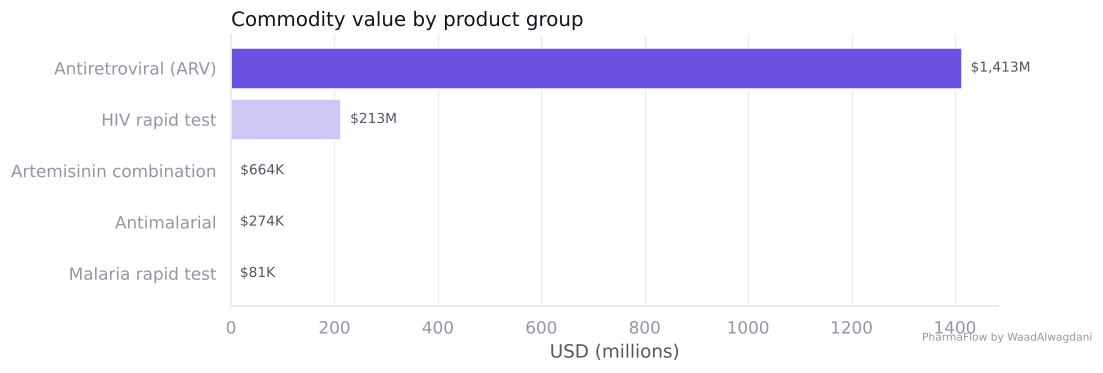

In [16]:
fig = viz.value_by_product(df); fig.savefig("../reports/figures/value_by_product.png"); plt.show()

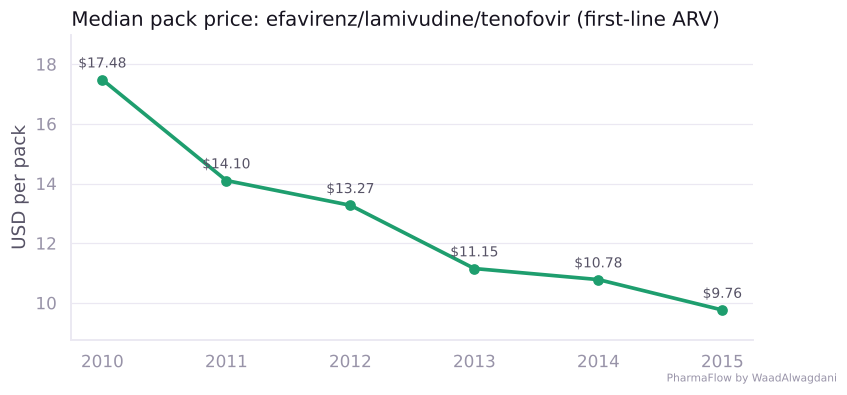

,median_pack_price,count
year,,
2010,17.48,2
2011,14.10,5
2012,13.27,27
2013,11.15,70
2014,10.78,97
2015,9.76,85


In [17]:
tle = metrics.price_trend(df, "Efavirenz/Lamivudine/Tenofovir")
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(tle.index, tle["median_pack_price"], marker="o", color=viz.GREEN, lw=2.4)
for x, y in tle["median_pack_price"].items():
    ax.annotate(f"${y:.2f}", (x, y), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=9, color=viz.INK2)
ax.set(title="Median pack price: efavirenz/lamivudine/tenofovir (first-line ARV)", ylabel="USD per pack", xlabel="")
ax.set_ylim(tle["median_pack_price"].min() - 1, tle["median_pack_price"].max() + 1.5)
fig.text(0.995, 0.005, viz.SIGNATURE, ha="right", fontsize=7, color=viz.INK3)
fig.savefig("../reports/figures/tle_price.png"); plt.show()
tle

The first-line fixed-dose ARV dropped **from $17.48 to $9.76 per pack (−44%)** between 2010 and 2015, while its volume grew from 2 to 85+ lines a year.

## 12. Conclusions
1. **88.5% of shipment lines arrived on time.** Reliability fell sharply in 2011 (76.5%) and stayed below the 2006–2009 level.
2. **When late, shipments were late by a median of 12 days**, long enough to matter for continuous ARV therapy.
3. **Direct drop was more punctual than RDC fulfilment** (94.7% vs 82.8%), and RDC freight cost more as a share of value.
4. **Air freight costs about 6× more per kg than ocean**, but trucks, not ocean, were the least punctual mode.
5. **Price of first-line TLE fell 44%** in five years, a sign of generic competition and pooled procurement.

**Recommendations for a pharmaceutical supply chain**
* Set safety stock from the 90th-percentile delay of each lane, not the average.
* Review RDC replenishment for the lowest-performing countries (DR Congo, Mozambique).
* Use truck routes only where buffer stock can absorb a 1–4 week delay.
* Consider air charter or ocean freight for bulky, non-urgent ARV shipments.

---
*PharmaFlow by WaadAlwagdani · © 2026 Waad Alwagdani, PharmD. All rights reserved.*